# Fitting TCM-SR parameters with EM

This notebook fits the look-ahead `gamma` and the forward weight `asymmetry` of a `TCM_SR` dynamic to replay spikes with generalized expectation maximization (EM), and cross-checks the result against the marginal likelihood computed directly.

It uses the same simulation as `Classifying_with_Sorted_Spikes_TCM_SR.ipynb`: the same settings (from `tcmsr_simulation_config.py`) and the same code (from `tcmsr_simulation.py`). Position is the directed loop $u$ of that notebook, so the latent state is (dynamic, position, running direction).

The model has three dynamics: stationary (`Identity`), TCM-SR (`TCM_SR`) and fragmented (`Uniform`). The discrete transition between them is held fixed at `DiagonalDiscrete(0.98)`.

Each EM iteration has two steps:

- **E-step.** From the smoothed posterior, compute the expected number of times the replay moved from bin $i$ to bin $j$ while entering the TCM-SR dynamic.
- **M-step.** Pick the `gamma` and `asymmetry` whose kernel $K$ maximizes $Q = \sum_{ij} E_{ij} \log K_{ij}$. The search is a coarse grid over log horizon and `asymmetry`, refined by a bounded Powell search, and it only accepts a candidate that raises $Q$. The data log likelihood can therefore never decrease.

The kernel is

$$M = (I - \gamma P)^{-1} P, \qquad A = \text{asymmetry} \cdot \text{rownorm}(M) + (1 - \text{asymmetry}) \cdot \text{rownorm}(M^\top M)$$

with $P$ counted over `movement_time_step = REPLAY_SPEEDUP * DECODE_BIN_S` of behavior (30 ms with the default settings), so that at `gamma=0` the kernel replays at `REPLAY_SPEEDUP` times the running speed. The horizon is `movement_time_step / (1 - gamma)` seconds of behavior.

In [1]:
%load_ext autoreload
%autoreload 2

import logging

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

sns.set(style='white', context='paper', font_scale=1.0)
logging.basicConfig(level=logging.WARNING)
np.random.seed(0)

## Settings

The shared simulation settings are in `tcmsr_simulation_config.py`, next to this notebook; change them there and rerun both notebooks. The settings below are specific to fitting: the replay data are `N_EVENTS` cycles of hover, TCM-SR and fragmented segments, generated from `TCM_SR(gamma=TRUE_GAMMA, asymmetry=TRUE_ASYMMETRY)`, and EM starts from `START_GAMMA` and `START_ASYMMETRY`.

In [2]:
from tcmsr_simulation_config import *
from tcmsr_simulation_config import print_settings

N_EVENTS = 50            # hover -> TCM-SR -> fragmented cycles in the replay data
TRUE_GAMMA = 0.8         # the generating kernel, as decoded in the classification notebook
TRUE_ASYMMETRY = 0.5
START_GAMMA = 0.2        # where EM starts
START_ASYMMETRY = 0.9
print_settings()

N_CELLS = 100
RUNNING_SPEED_CM_S = 80.0
RUNNING_SPEED_CV = 0.25
N_LAPS = 50
REPLAY_SPEEDUP = 10
DECODE_BIN_S = 0.003
PLACE_BIN_SIZE_CM = 2.0
REPLAY_PEAK_RATE_HZ = 20.0
EVENT_S = 0.2
IDEALIZED_SPIKES = False


## Simulate running on the directed loop

The animal runs back and forth on the track, each run at its own speed, and half the place cells fire only on the way out, half only on the way back (see the classification notebook). Unfolding the track into the directed loop $u$ ($u = x$ outbound, $2L - x$ inbound) makes every observed movement point forward in $u$. So $P$ is directional, and `asymmetry` is identifiable, without restricting the animal to run one way.

100 cells, 78043 bins of 3 ms (234 s of running)


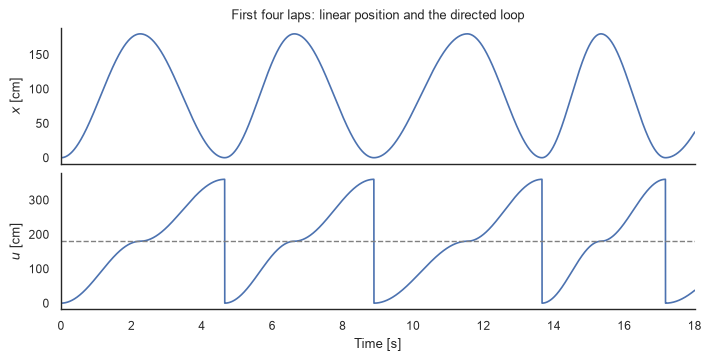

In [3]:
from tcmsr_simulation import simulate_run_data

run = simulate_run_data()
track_length, sampling_frequency = run.track_length, run.sampling_frequency
LOOP_LENGTH = 2 * track_length
print(f'{N_CELLS} cells, {run.time.size} bins of {1e3 * DECODE_BIN_S:g} ms '
      f'({run.time[-1]:.0f} s of running)')

plot_s = 4 * 2 * track_length / RUNNING_SPEED_CM_S
fig, axes = plt.subplots(2, 1, figsize=(7, 3.5), sharex=True, constrained_layout=True)
axes[0].plot(run.time, run.linear_distance)
axes[0].set_ylabel('$x$ [cm]')
axes[0].set_title('First four laps: linear position and the directed loop')
axes[1].plot(run.time, run.directional_position)
axes[1].axhline(track_length, color='grey', linestyle='--', linewidth=1)
axes[1].set_ylabel('$u$ [cm]')
axes[1].set_xlim((0, plot_s))
axes[1].set_xlabel('Time [s]')
sns.despine()

## Simulate replays from a known kernel

The generating kernel is `TCM_SR(gamma=TRUE_GAMMA, asymmetry=TRUE_ASYMMETRY)`, fit to the run data above: with the defaults a 0.15 s horizon (5 steps of $P$). The replay data repeat `N_EVENTS` times:

- `EVENT_S / 2` hovering at a random position.
- `EVENT_S` of a TCM-SR trajectory sampled from the generating kernel, one step per decoding bin, from a random start.
- `EVENT_S / 2` jumping uniformly at random.

Spikes are Poisson from the place fields along the trajectory, as in the classification notebook.

19.9 s of replay data; 15.3 spikes per TCM-SR segment


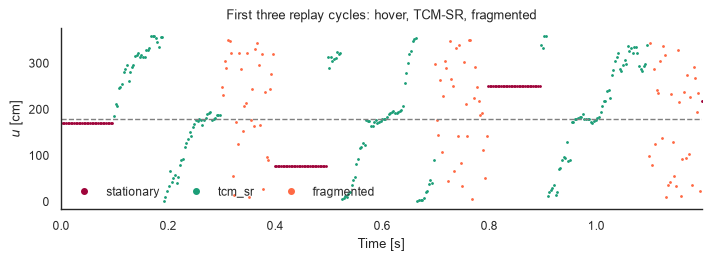

In [4]:
from replay_trajectory_classification import (
    DiagonalDiscrete, Environment, Identity, SortedSpikesClassifier, TCM_SR, Uniform)
from tcmsr_simulation import ReplayPaths, make_replay_spikes

STATE_NAMES = ['stationary', 'tcm_sr', 'fragmented']
# One step of P per decoding bin replays behavior REPLAY_SPEEDUP times faster.
MOVEMENT_TIME_STEP = REPLAY_SPEEDUP * DECODE_BIN_S


def horizon_s(gamma):
    return MOVEMENT_TIME_STEP / (1 - gamma)


def make_tcm_sr(**kwargs):
    return TCM_SR(movement_time_step=MOVEMENT_TIME_STEP, sampling_frequency=sampling_frequency,
                  **kwargs)


def make_classifier(tcm_sr):
    return SortedSpikesClassifier(
        environments=Environment(place_bin_size=PLACE_BIN_SIZE_CM),
        continuous_transition_types=[[Identity(), tcm_sr,    Uniform()],
                                     [Identity(), tcm_sr,    Uniform()],
                                     [Uniform(),  Uniform(), Uniform()]],
        discrete_transition_type=DiagonalDiscrete(0.98),
        sorted_spikes_algorithm='spiking_likelihood_kde',
        sorted_spikes_algorithm_params={'position_std': 3.0})


generator = make_classifier(make_tcm_sr(gamma=TRUE_GAMMA, asymmetry=TRUE_ASYMMETRY))
generator.fit(run.directional_position, run.spikes)
environment = generator.environments[0]
true_kernel = generator.continuous_state_transition_[1, 1].copy()
paths = ReplayPaths(environment, LOOP_LENGTH, kernel=true_kernel)

n_event_bins = int(round(EVENT_S / DECODE_BIN_S))
half = n_event_bins // 2
rng = np.random.default_rng(1)
replay_position, true_state = [], []
for _ in range(N_EVENTS):
    replay_position += [paths.stationary(rng.choice(paths.interior_centers), half),
                        paths.tcm_sr(rng.choice(paths.interior_centers), rng, n_event_bins),
                        paths.fragmented(rng, half)]
    true_state += ['stationary'] * half + ['tcm_sr'] * n_event_bins + ['fragmented'] * half
replay_position = np.concatenate(replay_position)
true_state = np.asarray(true_state)
replay_spikes = make_replay_spikes(replay_position, rng, run.place_field_means, track_length)
replay_time = np.arange(replay_position.size) / sampling_frequency
cycle_s = (2 * half + n_event_bins) * DECODE_BIN_S
print(f'{replay_time[-1]:.1f} s of replay data; '
      f'{replay_spikes[true_state == "tcm_sr"].sum() / N_EVENTS:.1f} spikes per TCM-SR segment')

fig, ax = plt.subplots(figsize=(7, 2.5), constrained_layout=True)
for state, color in zip(STATE_NAMES, ['#9f043a', '#1b9e77', '#ff6944']):
    is_state = true_state == state
    ax.plot(replay_time[is_state], replay_position[is_state], '.', markersize=2,
            color=color, label=state)
ax.axhline(track_length, color='grey', linestyle='--', linewidth=1)
ax.set_xlim((0, 3 * cycle_s))
ax.set_xlabel('Time [s]')
ax.set_ylabel('$u$ [cm]')
ax.set_title('First three replay cycles: hover, TCM-SR, fragmented')
ax.legend(frameon=False, ncol=3, markerscale=4)
sns.despine()

## Fit `gamma` and `asymmetry` by EM

The fitted instance starts away from the truth, at `START_GAMMA` and `START_ASYMMETRY`. `learn` names the parameters to fit, and `estimate_discrete_transition=False` holds the discrete matrix fixed. The initial conditions are re-estimated, as `estimate_parameters` does by default.

In [5]:
tcm_sr = make_tcm_sr(gamma=START_GAMMA, asymmetry=START_ASYMMETRY, learn=('gamma', 'asymmetry'))
classifier = make_classifier(tcm_sr)

results, data_log_likelihoods = classifier.estimate_parameters(
    fit_args=dict(position=run.directional_position, spikes=run.spikes),
    predict_args=dict(spikes=replay_spikes, time=replay_time, state_names=STATE_NAMES),
    estimate_continuous_transition=True,
    estimate_discrete_transition=False,
    max_iter=30,
    verbose=False,
)

history = [step[((0, 1), (1, 1))] for step in classifier.continuous_transition_parameter_history_]
horizons = [horizon_s(START_GAMMA)] + [horizon_s(step['gamma']) for step in history]
asymmetries = [START_ASYMMETRY] + [step['asymmetry'] for step in history]
print(f'{len(history)} iterations')
print(f'horizon:   true {horizon_s(TRUE_GAMMA):.3f} s, fitted {horizons[-1]:.3f} s '
      f'(gamma {tcm_sr.gamma:.3f}, true {TRUE_GAMMA})')
print(f'asymmetry: true {TRUE_ASYMMETRY:.2f}, fitted {tcm_sr.asymmetry:.3f}')
print('smallest change in data log likelihood between iterations:',
      np.diff(data_log_likelihoods).min())

  0%|          | 0/100 [00:00<?, ?it/s]

25 iterations
horizon:   true 0.150 s, fitted 0.153 s (gamma 0.804, true 0.8)
asymmetry: true 0.50, fitted 0.504
smallest change in data log likelihood between iterations: 0.33408152272068037


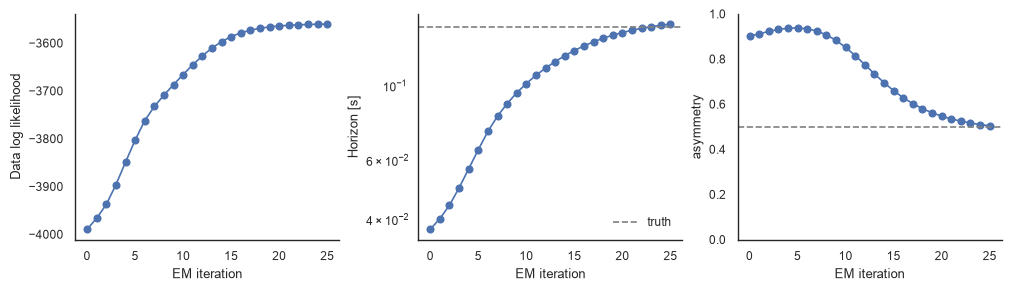

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(10, 2.8), constrained_layout=True)
iterations = np.arange(len(data_log_likelihoods))

axes[0].plot(iterations, data_log_likelihoods, marker='o')
axes[0].set_ylabel('Data log likelihood')

axes[1].plot(iterations, horizons, marker='o')
axes[1].axhline(horizon_s(TRUE_GAMMA), color='grey', linestyle='--', label='truth')
axes[1].set_yscale('log')
axes[1].set_ylabel('Horizon [s]')
axes[1].legend(frameon=False)

axes[2].plot(iterations, asymmetries, marker='o')
axes[2].axhline(TRUE_ASYMMETRY, color='grey', linestyle='--')
axes[2].set_ylim((0, 1))
axes[2].set_ylabel('asymmetry')

for ax in axes:
    ax.set_xlabel('EM iteration')
sns.despine()

## Cross-check against the marginal likelihood

`score_continuous_transition` sets candidate parameters, rebuilds the kernel, runs only the forward pass on the cached spike likelihood, and restores the model. Each call costs one full forward pass, so a grid is far more expensive than EM, but it checks EM's answer without relying on the E-step. The EM estimate should sit at the peak. The grid runs from a one-step horizon (`gamma=0`) to 100 steps of $P$.

EM estimate minus best grid point: 9.04 nats


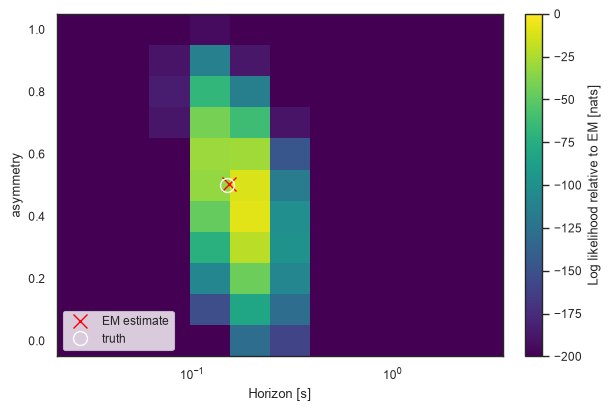

In [7]:
grid_horizons = np.logspace(np.log10(MOVEMENT_TIME_STEP), np.log10(100 * MOVEMENT_TIME_STEP), 11)
grid_asymmetries = np.linspace(0.0, 1.0, 11)
scores = np.array([[classifier.score_continuous_transition(
                        tcm_sr, gamma=max(0.0, 1 - MOVEMENT_TIME_STEP / horizon),
                        asymmetry=asymmetry)
                    for horizon in grid_horizons]
                   for asymmetry in grid_asymmetries])
em_score = classifier.score_continuous_transition(tcm_sr)
print(f'EM estimate minus best grid point: {em_score - scores.max():.2f} nats')

fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
mesh = ax.pcolormesh(grid_horizons, grid_asymmetries, scores - em_score,
                     vmin=-200, vmax=0, cmap='viridis', shading='nearest')
fig.colorbar(mesh, ax=ax, label='Log likelihood relative to EM [nats]')
ax.plot(horizons[-1], tcm_sr.asymmetry, marker='x', color='red', markersize=10,
        linestyle='none', label='EM estimate')
ax.plot(horizon_s(TRUE_GAMMA), TRUE_ASYMMETRY, marker='o', markerfacecolor='none',
        color='white', markersize=10, linestyle='none', label='truth')
ax.set_xscale('log')
ax.set_xlabel('Horizon [s]')
ax.set_ylabel('asymmetry')
ax.legend(frameon=True, facecolor='white', loc='lower left')

In [8]:
# Direct maximization of the marginal likelihood, the route used on real data where EM
# is slow: refine the best grid point above with Nelder-Mead in (log horizon, asymmetry).
import pandas as pd
from scipy.optimize import minimize


def negative_log_likelihood(parameters):
    log_horizon, asymmetry = parameters
    if not (np.exp(log_horizon) >= MOVEMENT_TIME_STEP and 0.0 <= asymmetry <= 1.0):
        return np.inf
    return -classifier.score_continuous_transition(
        tcm_sr, gamma=1 - MOVEMENT_TIME_STEP / np.exp(log_horizon), asymmetry=asymmetry)


best = np.unravel_index(scores.argmax(), scores.shape)
x0 = np.array([np.log(grid_horizons[best[1]]), grid_asymmetries[best[0]]])
refined = minimize(negative_log_likelihood, x0, method='Nelder-Mead',
                   options=dict(maxfev=40, xatol=0.01, fatol=0.1,
                                initial_simplex=x0 + np.array([[0, 0], [0.5, 0], [0, 0.1]])))
nm_horizon, nm_asymmetry = np.exp(refined.x[0]), refined.x[1]

true_score = classifier.score_continuous_transition(
    tcm_sr, gamma=TRUE_GAMMA, asymmetry=TRUE_ASYMMETRY)
pd.DataFrame({
    'horizon [s]': [horizon_s(TRUE_GAMMA), horizons[-1], nm_horizon],
    'gamma': [TRUE_GAMMA, tcm_sr.gamma, 1 - MOVEMENT_TIME_STEP / nm_horizon],
    'asymmetry': [TRUE_ASYMMETRY, tcm_sr.asymmetry, nm_asymmetry],
    'log likelihood vs EM [nats]': [true_score - em_score, 0.0, -refined.fun - em_score],
    'cost': ['', f'{len(history)} EM iterations',
             f'{scores.size} + {refined.nfev} forward passes'],
}, index=['truth', 'EM', 'grid + Nelder-Mead']).round(3)

,horizon [s],gamma,asymmetry,log likelihood vs EM [nats],cost
truth,0.150,0.800,0.500,-0.598,
EM,0.153,0.804,0.504,0.000,25 EM iterations
grid + Nelder-Mead,0.161,0.813,0.475,0.780,121 + 27 forward passes


## Fitted and true kernels, and the classification

The fitted kernel row from the middle of the outbound half of the loop overlays the generating one. Below it, the decoded probability of each dynamic is compared with the segment labels of the simulation.

stationary: 0.84 of bins decoded correctly
    tcm_sr: 0.88 of bins decoded correctly
fragmented: 0.88 of bins decoded correctly


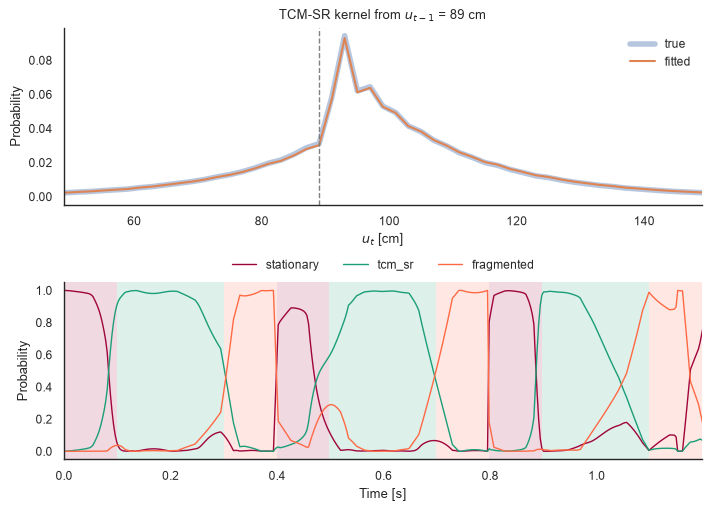

In [9]:
mid_bin = paths.nearest_bin(track_length / 2)  # middle of the outbound half
bin_centers = paths.bin_centers
fitted_kernel = classifier.continuous_state_transition_[1, 1]

fig, axes = plt.subplots(2, 1, figsize=(7, 5), constrained_layout=True)
axes[0].plot(bin_centers, true_kernel[mid_bin], linewidth=4, alpha=0.4, label='true')
axes[0].plot(bin_centers, fitted_kernel[mid_bin], linewidth=1.5, label='fitted')
axes[0].axvline(bin_centers[mid_bin], color='grey', linestyle='--', linewidth=1)
axes[0].set_xlim((bin_centers[mid_bin] - 40, bin_centers[mid_bin] + 60))
axes[0].set_xlabel(r'$u_{t}$ [cm]')
axes[0].set_ylabel('Probability')
axes[0].set_title(rf'TCM-SR kernel from $u_{{t-1}}$ = {bin_centers[mid_bin]:.0f} cm')
axes[0].legend(frameon=False)

probability = results.acausal_posterior.sum('position')
state_colors = dict(zip(STATE_NAMES, ['#9f043a', '#1b9e77', '#ff6944']))
# Shade the ground-truth state behind the decoded probabilities.
change = np.flatnonzero(true_state[1:] != true_state[:-1]) + 1
for start, stop in zip(np.r_[0, change], np.r_[change, true_state.size]):
    axes[1].axvspan(start / sampling_frequency, stop / sampling_frequency,
                    color=state_colors[true_state[start]], alpha=0.15, linewidth=0)
for state, color in state_colors.items():
    axes[1].plot(replay_time, probability.sel(state=state), label=state, linewidth=1, color=color)
axes[1].set_xlim((0, 3 * cycle_s))
axes[1].set_xlabel('Time [s]')
axes[1].set_ylabel('Probability')
axes[1].legend(frameon=False, ncol=3, loc='lower center', bbox_to_anchor=(0.5, 1.0))
sns.despine()

decoded = np.asarray(STATE_NAMES)[probability.values.argmax(axis=1)]
for state in STATE_NAMES:
    is_state = true_state == state
    print(f'{state:>10}: {np.mean(decoded[is_state] == state):.2f} of bins decoded correctly')

## Summary

Starting from a 0.04 s horizon (`gamma=0.2`) and `asymmetry=0.9`, EM recovers the generating kernel in 25 iterations: a 0.153 s horizon (`gamma` 0.804) against 0.150 s (`gamma` 0.8), and `asymmetry` 0.504 against 0.5. The data log likelihood rises at every iteration, and no point of the forward-pass grid beats the EM estimate (EM is 9 nats above the best grid point). The fitted kernel overlays the generating one. This is from 50 replay cycles with about 15 spikes per 200 ms TCM-SR segment. Maximizing the marginal likelihood directly, by refining the best grid point with Nelder–Mead, lands next to EM: a 0.161 s horizon and `asymmetry` 0.475. That is 0.8 nats above EM's estimate, so the likelihood is flat to within a nat between the two. It costs 148 forward passes, against EM's 25 iterations.

The grid also shows the shape of the likelihood:

- **The horizon is sharply determined.** On the grid, horizons one step away (a factor of about 1.6) cost tens of nats or more.
- **`asymmetry` is less sharply determined.** Values within about 0.15 of the truth are within a few tens of nats, and `asymmetry` near 1 (no backward moves) is ruled out.
- **The two trade off mildly.** A longer horizon prefers a slightly lower `asymmetry`.

`asymmetry` is identifiable here because $P$ is directional on the directed loop: every observed movement points forward in $u$. Fitting on linear position of back-and-forth running would give a nearly symmetric $P$, and the likelihood would be almost flat in `asymmetry`.